In [1]:
import os
import sys

# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

In [2]:
from dashsrc.plot_components.plots import plot_EnsambleEncondings
from dashsrc.plot_components.plots import plot_EnsembleChoiceEncoding


In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# %matplotlib qt
%matplotlib widget

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger

from dashsrc.plot_components.plot_wrappers.data_selection import group_filter_data

from analytics_processing.modality_loading import session_modality_from_nas
from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames

# import GridSpecFromSubplotSpec
from matplotlib.gridspec import GridSpecFromSubplotSpec
import scipy.stats as stats
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap, Normalize



In [4]:
data = {}
nas_dir = C.device_paths()[0]
output_dir = os.path.join(nas_dir, 'Simon', 'lm4')
Logger().init_logger(None, None, logging_level="INFO")

In [5]:
animal_ids = [6]
paradigm_ids = [1100]
session_ids = None

In [6]:
session_dirs, _ = sessionlist_fullfnames_from_args(paradigm_ids, animal_ids, session_ids)
session_names = fullfnames2snames(session_dirs)
session_to_dt_session = {sn[:16]:i for i,sn in enumerate(session_names)}
session_names

['2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min',
 '2024-11-14_16-40_rYL006_P1100_LinearTrackStop_21min',
 '2024-11-15_15-48_rYL006_P1100_LinearTrackStop_35min',
 '2024-11-20_17-46_rYL006_P1100_LinearTrackStop_22min',
 '2024-11-21_17-22_rYL006_P1100_LinearTrackStop_25min',
 '2024-11-22_16-01_rYL006_P1100_LinearTrackStop_24min',
 '2024-11-25_16-25_rYL006_P1100_LinearTrackStop_18min',
 '2024-11-26_16-39_rYL006_P1100_LinearTrackStop_25min',
 '2024-11-27_16-11_rYL006_P1100_LinearTrackStop_31min',
 '2024-11-28_17-41_rYL006_P1100_LinearTrackStop_30min',
 '2024-11-29_17-21_rYL006_P1100_LinearTrackStop_28min',
 '2024-12-02_16-09_rYL006_P1100_LinearTrackStop_28min',
 '2024-12-03_16-23_rYL006_P1100_LinearTrackStop_30min',
 '2024-12-04_18-06_rYL006_P1100_LinearTrackStop_30min',
 '2024-12-06_16-49_rYL006_P1100_LinearTrackStop_25min',
 '2024-12-09_17-45_rYL006_P1100_LinearTrackStop_26min',
 '2024-12-10_17-20_rYL006_P1100_LinearTrackStop_30min',
 '2024-12-11_17-42_rYL006_P1100_LinearTrackStop_

In [7]:
trialw_beh = analytics.get_analytics('BehaviorTrialwise', session_names=session_names[:8])

trialw_beh.index = trialw_beh.index.droplevel(('animal_id', 'paradigm_id', 'entry_id'))
trialw_beh.index = trialw_beh.index.map(lambda x: session_to_dt_session[x[:16]] if x[:16] in session_to_dt_session else x)
trialw_beh

/home/vrmaster/Projects/VirtualReality/analysisVR/analytics_processing/analytics.py:664: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  aggr = pd.concat(aggr)
2026-08-03 19:42:05,453|INFO|2350025|analytics|get_analytics
	Returning BehaviorTrialwise for 8 sessions.


,trial_id,trial_start_frame,trial_start_pc_timestamp,trial_end_frame,trial_end_pc_timestamp,trial_pc_duration,trial_outcome,trial_start_ephys_timestamp,trial_end_ephys_timestamp,velocity_threshold_at_R1,...,reward1Zone_enter_ephys_t,reward1Zone_exit_ephys_t,reward2Zone_enter_ephys_t,reward2Zone_exit_ephys_t,startZone_enter_ephys_t,startZone_exit_ephys_t,visibleCue_enter_ephys_t,visibleCue_exit_ephys_t,trial_start_ephys_patched,trial_end_ephys_patched
session_id,,,,,,,,,,,,,,,,,,,,,
0,1,14196,1731592884285890,14864,1731592895460142,11174252,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,2,14986,1731592897508073,15673,1731592909008677,11500604,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,3,15795,1731592911043475,16496,1731592922729898,11686423,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,4,16618,1731592924764315,17314,1731592936370725,11606410,0,NaN,NaN,0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,5,17436,1731592938409486,18056,1731592948755828,10346342,0,NaN,NaN,0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,83,92638,1732637022706415,93398,1732637035373051,12666636,2,1.459351e+09,1.472019e+09,0.3,...,1.462218e+09,1.463251e+09,1.463985e+09,1.467602e+09,1.459351e+09,1.460351e+09,1.460368e+09,1.460784e+09,0.0,0.0
7,84,93520,1732637037408035,94349,1732637051224419,13816384,20,1.474053e+09,1.487870e+09,0.3,...,1.476803e+09,1.480020e+09,1.485954e+09,1.487404e+09,1.474053e+09,1.475036e+09,1.475053e+09,1.475403e+09,0.0,0.0
7,85,94471,1732637053259061,95357,1732637068026439,14767378,21,1.489904e+09,1.504672e+09,0.3,...,1.494071e+09,1.497238e+09,1.501522e+09,1.503922e+09,1.489904e+09,1.492471e+09,1.492488e+09,1.492838e+09,0.0,0.0


In [8]:
plt.rcParams.update({
    'font.size': 15,           # general font size
    'axes.titlesize': 15,      # subplot title
    'axes.labelsize': 15,      # x and y labels
    'xtick.labelsize': 15,     # x tick labels
    'ytick.labelsize': 15,     # y tick labels
    'legend.fontsize': 15,     # legend
})

Session 0: n_R1: 25/125, n_R2: 13/125
Session 1: n_R1: 13/102, n_R2: 16/102
Session 2: n_R1: 41/121, n_R2: 29/121
Session 3: n_R1: 12/67, n_R2: 11/67
Session 4: n_R1: 25/67, n_R2: 25/67
Session 5: n_R1: 23/75, n_R2: 19/75
Session 6: n_R1: 7/55, n_R2: 18/55
Session 7: n_R1: 51/87, n_R2: 39/87


/tmp/ipykernel_2347049/3058763103.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  a_trialw_beh.loc[:,'n_R_1st_location'] = n_R_1st_location.values
/tmp/ipykernel_2347049/3058763103.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  a_trialw_beh.loc[:,'n_R_2nd_location'] = n_R_2nd_location.values
/tmp/ipykernel_2347049/3058763103.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in t

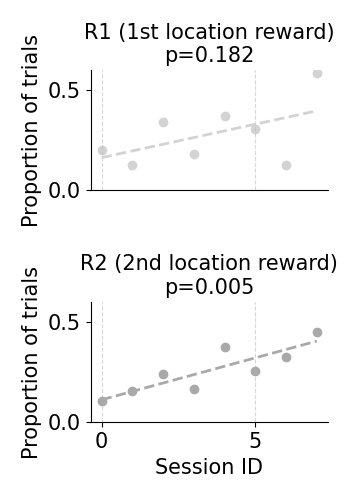

In [18]:
plt.close('all')
fig, axes = plt.subplots(figsize=(3.5,5), nrows=2, sharex=True)
x, y_loc1, y_loc2 = [], [], []
for s_id in trialw_beh.index.unique('session_id'):
    # print(s_id)
    a_trialw_beh = trialw_beh.loc[s_id]
    n_R_1st_location = a_trialw_beh.trial_outcome %5
    a_trialw_beh.loc[:,'n_R_1st_location'] = n_R_1st_location.values
    n_R_2nd_location = a_trialw_beh.trial_outcome //10
    a_trialw_beh.loc[:,'n_R_2nd_location'] = n_R_2nd_location.values
    n = len(a_trialw_beh)
    # print(a_trialw_beh[['trial_outcome', 'n_R_1st_location', 'n_R_2nd_location']].to_string())
    print(f"Session {s_id}: n_R1: {(n_R_1st_location>=1).sum()}/{n}, n_R2: {(n_R_2nd_location>=1).sum()}/{n}")
    
    # print(f"Session {s_id}: 1st loc R proportion: {(n_R_1st_location>1).sum()/n:.2f}, 2nd loc R proportion: {(n_R_2nd_location>1).sum()/n:.2f}")
    x.append(s_id)
    y_loc1.append((n_R_1st_location>=1).sum()/n)
    # y_loc1
    y_loc2.append((n_R_2nd_location>=1).sum()/n)

    axes[0].scatter([s_id,], [y_loc1[-1]], label='1st location R' if s_id == 0 else None, color='lightgrey')
    axes[1].scatter([s_id,], [y_loc2[-1]], label='2nd location R' if s_id == 0 else None, color='darkgrey')

# linear fit
x_num = np.arange(len(x))
slope, intercept, r_value, p_value, std_err = stats.linregress(x_num, y_loc1)
axes[0].plot(x, intercept + slope * x_num, '--', label=f'Fit: slope={slope:.3f}, p={p_value:.3f}', color='lightgrey', linewidth=2)
axes[0].set_title(f'R1 (1st location reward)\np={p_value:.3f}')

slope, intercept, r_value, p_value, std_err = stats.linregress(x_num, y_loc2)
axes[1].plot(x, intercept + slope * x_num, '--', label=f'Fit: slope={slope:.3f}, p={p_value:.3f}', color='darkgrey', linewidth=2)
axes[1].set_title(f'R2 (2nd location reward)\np={p_value:.3f}')

axes[1].set_xlabel('Session ID')
axes[0].set_ylabel('Proportion of trials')
axes[1].set_ylabel('Proportion of trials')
axes[0].set_ylim(0, .6)
axes[1].set_ylim(0, .6)
axes[0].tick_params(axis='x', which='both', bottom=False, labelbottom=False)
# gridlines
axes[0].grid(axis='x', alpha=0.5, linestyle='--')
axes[1].grid(axis='x', alpha=0.5, linestyle='--')
# removee all spines
[ax.spines[['top', 'right']].set_visible(False) for ax in axes]



fig.tight_layout(h_pad=2.5)
plt.show()

fname = os.path.join(output_dir, 'double_stop_performance.svg')
fig.savefig(fname, format='svg', dpi=300)

In [68]:
choices_dict

{0: {('Cue1', 'R1', 'R2'): 10,
  ('Cue1', 'R1', 'notR2'): 15,
  ('Cue1', 'notR1', 'R2'): 3,
  ('Cue1', 'notR1', 'notR2'): 97},
 7: {('Cue1', 'R1', 'R2'): 32,
  ('Cue1', 'R1', 'notR2'): 19,
  ('Cue1', 'notR1', 'R2'): 7,
  ('Cue1', 'notR1', 'notR2'): 29}}

In [69]:
import plotly.graph_objects as go
from collections import defaultdict

def compute_node_values(data):
    """Compute total value flowing through each node."""
    node_value = defaultdict(float)
    for path, val in data.items():
        for node in path:
            node_value[node] += val
    return node_value

def organize_nodes_by_column(node_meta, node_value):
    """Group nodes by their x-coordinate."""
    columns = defaultdict(list)
    for node_id, meta in node_meta.items():
        x = meta["x"]
        columns[x].append((node_id, node_value[node_id]))
    return columns

def compute_y_positions(columns, node_meta, pad=0.02):
    """Compute vertical positions for nodes in each column."""
    final_nodes = []
    
    # Define preferred order for nodes at each x position
    preferred_order = {
        0.5: ['R1', 'notR1'],      # R1 on top
        1.0: ['R2', 'notR2'],      # R2 on top
    }
    
    for x in sorted(columns.keys()):
        group = columns[x]
        
        # If we have a preferred order for this column, use it
        if x in preferred_order:
            order_map = {node_id: i for i, node_id in enumerate(preferred_order[x])}
            ordered_group = sorted(group, key=lambda item: order_map.get(item[0], 999))
        else:
            # Otherwise sort by descending value
            ordered_group = sorted(group, key=lambda x: -x[1])
        
        # Compute normalized vertical positions
        total = sum(val for _, val in ordered_group)
        y_cursor = 0.0
        
        for node_id, val in ordered_group:
            height = val / total * (1 - pad * (len(ordered_group) - 1))
            y_center = y_cursor + height / 2
            
            final_nodes.append({
                "id": node_id,
                "label": node_meta[node_id]["label"],
                "color": node_meta[node_id]["color"],
                "x": node_meta[node_id]["x"],
                "y": y_center,
                "height": height
            })
            y_cursor += height + pad
    
    return final_nodes

def build_links(data, label_index, win_outcomes, lose_outcomes):
    """Build source, target, value arrays for Sankey links with win/lose coloring."""
    sources, targets, values, link_colors = [], [], [], []
    
    WIN_COLOR = 'rgba(79,212,79,0.4)'  # light green
    LOSE_COLOR = 'rgba(214,14,14,0.15)'  # light red
    NEUTRAL_COLOR = 'rgba(128,128,128,0.3)'  # gray
    
    for (cue, r1, r2), val in data.items():
        # Cue → R1
        sources.append(label_index[cue])
        targets.append(label_index[r1])
        values.append(val)
        
        # Color first link: green if stop (R1), red if skip (notR1)
        if r1 == 'R1':
            link_colors.append(WIN_COLOR)
        elif r1 == 'notR1':
            link_colors.append(LOSE_COLOR)
        else:
            link_colors.append(NEUTRAL_COLOR)
        
        # R1 → R2
        sources.append(label_index[r1])
        targets.append(label_index[r2])
        values.append(val)
        
        # Color second link: green if stop (R2), red if skip (notR2)
        if r2 == 'R2':
            link_colors.append(WIN_COLOR)
        elif r2 == 'notR2':
            link_colors.append(LOSE_COLOR)
        else:
            link_colors.append(NEUTRAL_COLOR)
    
    return sources, targets, values, link_colors

def render_sankey(data, node_meta, win_outcomes=None, lose_outcomes=None, 
                  title="Sankey Diagram", height=400, width=600):
    """
    Render a Sankey diagram with colored links.
    
    Parameters:
    -----------
    data : dict
        Dictionary with (cue, r1, r2) tuples as keys and flow values as values
        Example: {('Cue1', 'R1', 'R2'): 10, ('Cue1', 'R1', 'notR2'): 5, ...}
    
    node_meta : dict
        Dictionary with node metadata
        Example: {'Cue1': {'label': 'Cue1', 'color': 'orange', 'x': 0.0},
                  'R1': {'label': 'Stop', 'color': 'grey', 'x': 0.5}, ...}
    
    win_outcomes : set or list, optional
        Set of (cue, r1, r2) tuples that represent winning outcomes (colored green)
        Example: {('Cue1', 'R1', 'R2')}
    
    lose_outcomes : set or list, optional
        Set of (cue, r1, r2) tuples that represent losing outcomes (colored red)
        Example: {('Cue1', 'notR1', 'notR2')}
    
    title : str
        Plot title
    
    height, width : int
        Figure dimensions
    """
    if win_outcomes is None:
        win_outcomes = set()
    if lose_outcomes is None:
        lose_outcomes = set()
    
    # Compute node values and positions
    node_values = compute_node_values(data)
    columns = organize_nodes_by_column(node_meta, node_values)
    final_nodes = compute_y_positions(columns, node_meta)
    
    # Build label index
    label_index = {node["id"]: idx for idx, node in enumerate(final_nodes)}
    
    # Build links with colors
    sources, targets, values, link_colors = build_links(data, label_index, win_outcomes, lose_outcomes)
    
    # Create figure
    fig = go.Figure(go.Sankey(
        arrangement="fixed",
        node=dict(
            pad=15,
            thickness=15,
            line=dict(color='black', width=0.5),
            label=[n["label"] for n in final_nodes],
            color=[n["color"] for n in final_nodes],
            x=[n["x"] for n in final_nodes],
            y=[n["y"] for n in final_nodes],
        ),
        link=dict(
            line=dict(color='black', width=0.5),
            source=sources,
            target=targets,
            value=values,
            color=link_colors,
        )
    ))
    
    fig.update_layout(
        title_text=title,
        font_size=10,
        height=height,
        width=width,
    )
    
    return fig



In [70]:

  # Using session 7 data from previous analysis
node_meta = {
    'Cue1': {'label': 'Cue1', 'color': 'orange', 'x': 0.0},
    'R1': {'label': 'StopR1', 'color': 'darkgrey', 'x': 0.5},
    'notR1': {'label': 'SkipR1', 'color': 'darkgrey', 'x': 0.5},
    'R2': {'label': 'StopR2', 'color': 'lightgrey', 'x': 1.0},
    'notR2': {'label': 'SkipR2', 'color': 'lightgrey', 'x': 1.0},
}

# Define winning and losing outcomes
win_outcomes = {('Cue1', 'R1', 'R2')}  # Green: stopped at both locations
lose_outcomes = {('Cue1', 'notR1', 'notR2')}  # Red: skipped both locations

fig = render_sankey(choices_dict[0], node_meta, win_outcomes=win_outcomes, 
                   lose_outcomes=lose_outcomes, title="Session 00")
# fname = f"{output_dir}/session_00_sankey.svg"
# fig.write_image(fname)

fig.show()
fig = render_sankey(choices_dict[7], node_meta, win_outcomes=win_outcomes, 
                   lose_outcomes=lose_outcomes, title="Session 07")
fname = f"{output_dir}/session_07_sankey.svg"
fig.write_image(fname)
fig.show()

In [71]:
def extract_trial_numbers(encoding_data):
    trial_d = encoding_data[~encoding_data.trial_id.duplicated()]

    cue_1_data  = {
        ('Cue1', 'R1', 'R2'): ((trial_d.cue ==1) & (trial_d.choice_R1 == 1) & (trial_d.choice_R2 == 1)).sum().item(),
        ('Cue1', 'R1', 'notR2'): ((trial_d.cue ==1) & (trial_d.choice_R1 == 1) & (trial_d.choice_R2 == 0)).sum().item(),
        ('Cue1', 'notR1', 'R2'): ((trial_d.cue ==1) & (trial_d.choice_R1 == 0) & (trial_d.choice_R2 == 1)).sum().item(),
        ('Cue1', 'notR1', 'notR2'): ((trial_d.cue ==1) & (trial_d.choice_R1 == 0) & (trial_d.choice_R2 == 0)).sum().item(),
    }
    cue_2_data  = {
        ('Cue2', 'R1', 'R2'): ((trial_d.cue ==2) & (trial_d.choice_R1 == 1) & (trial_d.choice_R2 == 1)).sum().item(),
        ('Cue2', 'R1', 'notR2'): ((trial_d.cue ==2) & (trial_d.choice_R1 == 1) & (trial_d.choice_R2 == 0)).sum().item(),
        ('Cue2', 'notR1', 'R2'): ((trial_d.cue ==2) & (trial_d.choice_R1 == 0) & (trial_d.choice_R2 == 1)).sum().item(),
        ('Cue2', 'notR1', 'notR2'): ((trial_d.cue ==2) & (trial_d.choice_R1 == 0) & (trial_d.choice_R2 == 0)).sum().item(),
    }
    return cue_1_data, cue_2_data


trialw_beh = analytics.get_analytics('BehaviorTrialwise', session_names=session_names[:])

trialw_beh.index = trialw_beh.index.droplevel(('animal_id', 'paradigm_id', 'entry_id'))
trialw_beh.index = trialw_beh.index.map(lambda x: session_to_dt_session[x[:16]] if x[:16] in session_to_dt_session else x)
trialw_beh.columns

/home/vrmaster/Projects/VirtualReality/analysisVR/analytics_processing/analytics.py:663: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

2026-08-02 09:35:10,922|INFO|2150921|analytics|get_analytics
	Returning BehaviorTrialwise for 34 sessions.
Returning BehaviorTrialwise for 34 sessions.================================================================================

INFO	Task(Task-2) __main__:analytics.py:get_analytics()- Returning BehaviorTrialwise for 34 sessions.


Index(['trial_id', 'trial_start_frame', 'trial_start_pc_timestamp',
       'trial_end_frame', 'trial_end_pc_timestamp', 'trial_pc_duration',
       'trial_outcome', 'trial_start_ephys_timestamp',
       'trial_end_ephys_timestamp', 'velocity_threshold_at_R1',
       'maximum_reward_number', 'cue', 'both_R1_R2_rewarded',
       'velocity_threshold_at_R2', 'ITI_enter_ephys_t', 'ITI_exit_ephys_t',
       'afterCue_enter_ephys_t', 'afterCue_exit_ephys_t',
       'bewteenRewardZones_enter_ephys_t', 'bewteenRewardZones_exit_ephys_t',
       'choice_R1', 'choice_R1_correct', 'choice_R1_ephys_timestamp',
       'choice_R2', 'choice_R2_correct', 'choice_R2_ephys_timestamp',
       'endZone_enter_ephys_t', 'endZone_exit_ephys_t',
       'nextToCue_enter_ephys_t', 'nextToCue_exit_ephys_t',
       'reward1Zone_enter_ephys_t', 'reward1Zone_exit_ephys_t',
       'reward2Zone_enter_ephys_t', 'reward2Zone_exit_ephys_t',
       'startZone_enter_ephys_t', 'startZone_exit_ephys_t',
       'visibleCue_ent

In [72]:
# trialw_beh = trialw_beh.loc[15:15]
# idx = trialw_beh.index.values
# idx = idx - (trialw_beh.trial_id<27).astype(float)
# trialw_beh.index = idx
# trialw_beh.index.name = 'session_id'
# trialw_beh

In [73]:
plt.rcParams.update({
    'font.size': 15,           # general font size
    'axes.titlesize': 15,      # subplot title
    'axes.labelsize': 15,      # x and y labels
    'xtick.labelsize': 15,     # x tick labels
    'ytick.labelsize': 15,     # y tick labels
    'legend.fontsize': 15,     # legend
})

In [74]:
trialw_beh

,trial_id,trial_start_frame,trial_start_pc_timestamp,trial_end_frame,trial_end_pc_timestamp,trial_pc_duration,trial_outcome,trial_start_ephys_timestamp,trial_end_ephys_timestamp,velocity_threshold_at_R1,...,startZone_enter_ephys_t,startZone_exit_ephys_t,visibleCue_enter_ephys_t,visibleCue_exit_ephys_t,trial_start_ephys_patched,trial_end_ephys_patched,multi_reward_requires_stop,flip_Cue1R1_Cue2R2,prob_cue1_trial,movement_gain_scaler
session_id,,,,,,,,,,,,,,,,,,,,,
0,1,14196,1731592884285890,14864,1731592895460142,11174252,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,2,14986,1731592897508073,15673,1731592909008677,11500604,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,3,15795,1731592911043475,16496,1731592922729898,11686423,0,NaN,NaN,0.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,4,16618,1731592924764315,17314,1731592936370725,11606410,0,NaN,NaN,0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,5,17436,1731592938409486,18056,1731592948755828,10346342,0,NaN,NaN,0.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33,148,277065,1737985853927664,278340,1737985875178413,21250749,1,4.255993e+09,4.277245e+09,0.3,...,4.255993e+09,4.266594e+09,4.266610e+09,4.267411e+09,0.0,0.0,1.0,1.0,0.5,1.0
33,149,278462,1737985877213607,279902,1737985901219848,24006241,1,4.279278e+09,4.303286e+09,0.3,...,4.279278e+09,4.287583e+09,4.287600e+09,4.288384e+09,0.0,0.0,1.0,1.0,0.5,1.0
33,150,280024,1737985903260421,281307,1737985926338418,23077997,0,4.305323e+09,4.328404e+09,0.3,...,4.305323e+09,4.308242e+09,4.308259e+09,4.309142e+09,0.0,0.0,1.0,1.0,0.5,1.0


Session 8: Expert trials: 23.3 %, n=24
Session 9: Expert trials: 32.3 %, n=43
Session 10: Expert trials: 25.3 %, n=22
Session 11: Expert trials: 30.5 %, n=32
Session 12: Expert trials: 32.7 %, n=34
Session 13: Expert trials: 30.8 %, n=37
Session 14: Expert trials: 34.7 %, n=33
Session 15: Expert trials: 37.3 %, n=31


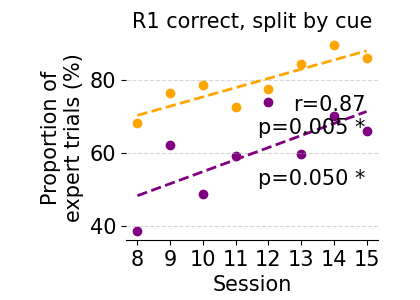

'/mnt/SpatialSequenceLearning/Simon/poster/session_07_sankey.svg'

In [76]:
plt.close('all' )
res_cue1 = []
res_cue2 = []
for s_id in trialw_beh.index.unique('session_id'):
    if (s_id <8) or (s_id >15):
        continue
    s_trialw_beh = trialw_beh.loc[s_id]
    expert_trials = s_trialw_beh[(s_trialw_beh['choice_R1_correct'] ==1) & 
                                 (s_trialw_beh['cue'] ==1) ]
    prop_expert_trials = len(expert_trials)/len(s_trialw_beh[s_trialw_beh['cue'] ==1]) *100
    # expert_trials = s_trialw_beh[(s_trialw_beh['choice_R1_correct'] ==1)]
    # prop_expert_trials = len(expert_trials)/len(s_trialw_beh) *100
    res_cue1.append((s_id, prop_expert_trials))
    
    expert_trials = s_trialw_beh[(s_trialw_beh['choice_R1_correct'] ==1) & 
                                 (s_trialw_beh['cue'] ==2) ]
    prop_expert_trials = len(expert_trials)/len(s_trialw_beh[s_trialw_beh['cue'] ==2]) *100
    # expert_trials = s_trialw_beh[(s_trialw_beh['choice_R2_correct'] ==1)]
    # prop_expert_trials = len(expert_trials)/len(s_trialw_beh) *100
    res_cue2.append((s_id, prop_expert_trials))
    
    print(f"Session {s_id}: Expert trials: {len(expert_trials)/len(s_trialw_beh) *100:.1f} %, n={len(expert_trials)}")
res_cue1 = np.array(res_cue1)
res_cue2 = np.array(res_cue2)

plt.figure(figsize=(4.2,3))
plt.scatter(res_cue1[:,0], res_cue1[:,1],  color='orange', label='R1 correct')


# # linear regression, with p value
# z = np.polyfit(res_cue1[:,0], res_cue1[:,1], 1)
# p = np.poly1d(z)
# plt.plot(res_cue1[:,0], p(res_cue1[:,0]), "r--", label=f'Fit: slope={z[0]:.3f}', color='orange')

# Linear fit
m, b = np.polyfit(res_cue1[:,0], res_cue1[:,1], 1)
plt.plot(res_cue1[:,0], m*res_cue1[:,0] + b, color='orange', linestyle='--', linewidth=2)
# Correlation
corr, pval = stats.pearsonr(res_cue1[:,0], res_cue1[:,1])
plt.text(0.95, 0.5, f'r={corr:.2f}\np={pval:.3f} *', transform=plt.gca().transAxes,
         verticalalignment='bottom', horizontalalignment='right')


plt.xlabel('Session ID')
plt.ylabel('Proportion of\nexpert trials (%)')
plt.title('R1 correct, split by cue')
# plt.ylim(0,50)
plt.xticks((8,9,10,11,12,13,14,15))
# y axis grid
plt.gca().yaxis.grid(True, linestyle='--', alpha=0.5)
# spines off
[plt.gca().spines[side].set_visible(False) for side in ['top', 'right', 'left']]
plt.subplots_adjust(left=0.3, bottom=.2)
plt.xlabel("Session")

# draw cue2
m, b = np.polyfit(res_cue2[:,0], res_cue2[:,1], 1)
plt.plot(res_cue2[:,0], m*res_cue2[:,0] + b, color='purple', linestyle='--', linewidth=2)
plt.scatter(res_cue2[:,0], res_cue2[:,1],  color='purple', label='R2 correct')
# Correlation
corr, pval = stats.pearsonr(res_cue2[:,0], res_cue2[:,1])
plt.text(0.95, 0.25, f'p={pval:.3f} *', transform=plt.gca().transAxes,
         verticalalignment='bottom', horizontalalignment='right')   



plt.show()

# save figure
# fname = 'export_perf_S8-15.svg'
# fname = 'export_perf_S8-15_split.svg'
# plt.savefig(os.path.join(output_dir, fname), format='svg', dpi=300)
os.path.join(output_dir, fname)

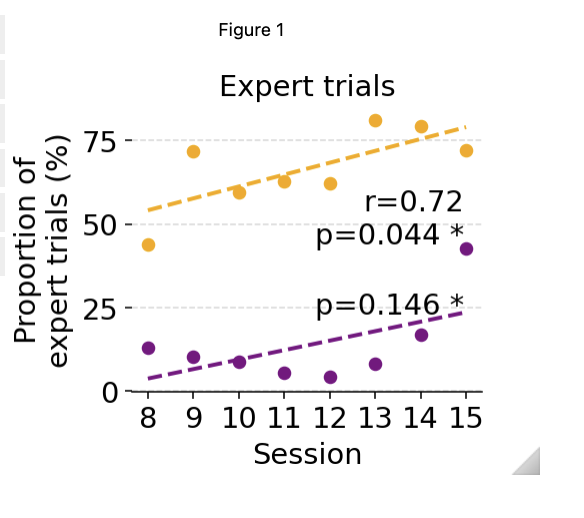

In [ ]:
#  %%
# Behavior sankey per session: cue-split choice_R1 -> choice_R2 flow, one Sankey per cue
# (2 per session, Cue1 stacked above Cue2 - same layout as the reference figure Simon
# shared), assembled into one grid via build_canvas (defined above, PIL/PNG-only - see its
# docstring): build_canvas already stacks a session's own image list vertically before
# placing sessions side by side, so passing [cue1_png, cue2_png] per session gets this
# layout for free. Vector-flow analog of the cue/choice_R1/trial_outcome barh breakdown in
# the "outlier plot" cell above, but split & restructured (Cue -> R1 -> R2, not
# Cue -> R1 -> outcome) to match that reference.
#
# Sankey construction follows go.Sankey usage in
# dashsrc/plot_components/plots/plot_EnsembleChoiceEncoding.py (build_sankey_figure), and
# reuses that file's node-position/annotation approach (see the "Node positions..." note
# from the previous version of this cell, kept below) - simplified since this flow has no
# per-neuron activation coloring to reproduce.
#
# Node positions are set explicitly (arrangement='fixed') and Plotly's native node.label is
# left blank in favor of custom fig.add_annotation calls - a first pass using the default
# auto-layout + native labels rendered illegibly (labels drawn on top of fully-opaque flow
# color, arrangement='snap' choosing not-very-meaningful positions). This mirrors
# add_node_annotations in plot_EnsembleChoiceEncoding.py, including its non-obvious
# y=1-node_y flip - Sankey's own node "y" is 0-at-top/1-at-bottom, but fig.add_annotation's
# xref='x'/yref='y' axes are standard 0-at-bottom/1-at-top, confirmed by rendering both ways
# in the scratchpad and comparing label placement against actual node color. That xref/yref
# combination also silently turns on a real cartesian axis (gridlines + tick labels) that
# has nothing to do with the Sankey itself, so it's explicitly hidden below.
#
# Per Simon's request: every flow is a neutral fill with a thin black perimeter except the
# full "correct" (rewarded) path - both the cue->R1 hop and the R1->R2 hop - which is filled
# green: Cue1's reward is at R1, so Cue1->StopR1 and StopR1->SkipR2 are both correct;
# Cue2's reward is at R2, so Cue2->SkipR1 ("the correct skipping" of R1) and
# SkipR1->StopR2 are both correct. Plain 2-node-per-column structure (Skip/Stop R1,
# Skip/Stop R2), matching build_links' cue/R1/R2 approach in
# dashsrc/plot_components/plots/plot_EnsembleChoiceEncoding.py - each (r1, r2) combination
# contributes two links (Cue->r1 and r1->r2, same value/color), so the Cue->R1 flow is
# genuinely split by eventual R2 destination rather than colored as one uniform block by R1
# choice alone (Simon: "the first sankey flow from node0 to node1 needs to be split, then
# you can selectively color only the correct flow").
#
# Several rounds of this looked like order-dependent Plotly bugs - a same-pair link getting
# "hidden", a crossing link visually "cutting through" another - each chased down with an
# isolated repro and fixed with increasingly complicated link-ordering logic (descending
# value sort, then a fixed per-cue draw order putting the correct flow's links last). None
# of it was the real cause. Re-running those exact repros with the non-highlighted links
# recolored from pure white to a visible gray (SANKEY_OTHER_COLOR) made every "hidden" and
# "discontinuous" flow appear fully intact, correctly proportioned, in its original
# (unordered) form. The entire fault was color, not geometry: a pure-white link is
# indistinguishable from the white page background, so a correctly-rendered white region
# reads as "missing" or "cut" wherever it isn't bordered by a differently-colored neighbor -
# exactly the two situations "hidden" and "discontinuous" flows kept showing up in. No link
# ordering logic is needed at all; a fixed, data-independent iteration (r1_order outer,
# r2_order inner - same every session) is both correct and simplest.
#
# The node carrying the reward (Stop R1 for Cue1, Stop R2 for Cue2) also gets a thick green
# perimeter - Plotly/Kaleido does NOT apply per-node line color/width arrays in static (PNG)
# export (confirmed with a minimal 3-node repro where a thick-green-outlined middle node
# rendered with the same thin black outline as its neighbors) - so that highlight is drawn
# as a separate fig.add_shape rectangle aligned to the node's own exact (x, y, height) from
# the layout below, rather than via node.line. For Cue2 that node sits in the rightmost (R2)
# column at x=0.999, and the shape's half-thickness pushes its right edge past x=1, clipped
# by the [0, 1] axis range used for annotation/shape placement (Simon: "the green box on the
# right is still... half cropped"). A first attempt widened that axis range to give the
# shape headroom - but the Sankey trace itself is NOT tied to this cartesian axis (it has
# its own independent domain, unaffected by axis range), so widening the axis instead
# desynced every shape/annotation's coordinate mapping from where the Sankey actually drew
# its nodes (a shape at the "same" x=0.999 now lands ~5% short of the true right edge),
# breaking every highlight box's alignment, not just Cue2's (Simon: "the boxes are even more
# off now"). Fixed by leaving the axis at exactly [0, 1] and instead clamping the shape's
# own x0/x1 to that range - the box is a hair narrower than the node on the clipped edge,
# but stays correctly aligned everywhere else.
import plotly.graph_objects as go
from matplotlib.colors import to_rgb

SANKEY_R1_LABELS = {False: 'Skip R1', True: 'Stop R1'}
SANKEY_R2_LABELS = {False: 'Skip R2', True: 'Stop R2'}
SANKEY_CUE_COLOR = {1: 'orange', 2: 'purple'}  # same cue colors as modality_colors above
SANKEY_REWARDED_NODE = {1: 'Stop R1', 2: 'Stop R2'}  # gets the thick green perimeter
SANKEY_CORRECT_FLOW = {1: ('Stop R1', 'Skip R2'), 2: ('Skip R1', 'Stop R2')}
SANKEY_CORRECT_COLOR = '#4caf50'
SANKEY_OTHER_COLOR = '#dcdcdc'  # NOT white - see note above, this was the entire bug
SANKEY_COLUMN_X = [0.001, 0.5, 0.999]  # plotly warns/misbehaves at exactly 0 or 1
SANKEY_FIG_WIDTH, SANKEY_FIG_HEIGHT = 460, 380
SANKEY_MARGIN = dict(t=40, b=10, l=10, r=140)
SANKEY_NODE_THICKNESS = 30  # wider bars
SANKEY_NODE_PAD = 25  # pixels - Plotly's own node-gap unit; our y-layout math must match it


def _rgba(color, alpha):
    r, g, b = to_rgb(color)
    return f'rgba({int(r*255)},{int(g*255)},{int(b*255)},{alpha})'


def build_cue_sankey(cue_trialw, cue_value, title):
    """choice_R1 -> choice_R2 flow for one session's trials of a single cue value."""
    cue_label = f'Cue{cue_value}'
    df = cue_trialw.copy()
    df['r1_label'] = df['choice_R1'].astype(bool).map(SANKEY_R1_LABELS)
    df['r2_label'] = df['choice_R2'].astype(bool).map(SANKEY_R2_LABELS)

    r1_to_r2 = df.groupby(['r1_label', 'r2_label']).size()
    r1_totals = df['r1_label'].value_counts()
    r1_order = list(SANKEY_R1_LABELS.values())
    r2_order = list(SANKEY_R2_LABELS.values())
    correct_r1, correct_r2 = SANKEY_CORRECT_FLOW[cue_value]

    node_totals = {cue_label: len(df)}
    for r1 in r1_order:
        node_totals[r1] = int(r1_totals.get(r1, 0))
    for r2 in r2_order:
        node_totals[r2] = int(r1_to_r2[r1_to_r2.index.get_level_values('r2_label') == r2].sum())

    # pad_frac converts Plotly's node.pad (a fixed PIXEL gap) into the same domain-height
    # fraction Plotly itself uses internally for stacking multiple nodes in one column -
    # using an unrelated fraction here (an earlier version hardcoded 0.08) silently drifts
    # from where Plotly actually draws each node, invisibly for a big node and obviously
    # ("only halfway") for a small one.
    domain_h = SANKEY_FIG_HEIGHT - SANKEY_MARGIN['t'] - SANKEY_MARGIN['b']
    pad_frac = SANKEY_NODE_PAD / domain_h

    columns = [[cue_label], r1_order, r2_order]
    labels, node_x, node_y, node_height = [], [], [], {}
    label_index = {}
    for x, column in zip(SANKEY_COLUMN_X, columns):
        total = sum(node_totals[node_id] for node_id in column) or 1
        y_cursor = 0.0
        for node_id in column:
            height = node_totals[node_id] / total * (1 - pad_frac * (len(column) - 1))
            label_index[node_id] = len(labels)
            labels.append(node_id)
            node_x.append(x)
            node_y.append(y_cursor + height / 2)
            node_height[node_id] = height
            y_cursor += height + pad_frac

    node_fill = [SANKEY_CUE_COLOR[cue_value] if l == cue_label else 'white' for l in labels]

    sources, targets, values, link_colors = [], [], [], []
    for r1 in r1_order:
        for r2 in r2_order:
            count = r1_to_r2.get((r1, r2), 0)
            if count <= 0:
                continue
            color = _rgba(SANKEY_CORRECT_COLOR, 0.7) if (r1, r2) == (correct_r1, correct_r2) else SANKEY_OTHER_COLOR
            sources.append(label_index[cue_label])
            targets.append(label_index[r1])
            values.append(count)
            link_colors.append(color)
            sources.append(label_index[r1])
            targets.append(label_index[r2])
            values.append(count)
            link_colors.append(color)

    fig = go.Figure(go.Sankey(
        arrangement='fixed',
        node=dict(pad=SANKEY_NODE_PAD, thickness=SANKEY_NODE_THICKNESS, label=[''] * len(labels),
                  x=node_x, y=node_y, color=node_fill, line=dict(color='black', width=1)),
        link=dict(source=sources, target=targets, value=values, color=link_colors,
                  line=dict(color='black', width=1)),
    ))

    domain_w = SANKEY_FIG_WIDTH - SANKEY_MARGIN['l'] - SANKEY_MARGIN['r']
    half_x = (SANKEY_NODE_THICKNESS / domain_w) / 2
    rewarded = SANKEY_REWARDED_NODE[cue_value]
    rx, ry, rh = node_x[label_index[rewarded]], node_y[label_index[rewarded]], node_height[rewarded]
    fig.add_shape(type='rect', xref='x', yref='y',
                  x0=max(rx - half_x, 0.0), x1=min(rx + half_x, 1.0),
                  y0=1 - (ry + rh / 2), y1=1 - (ry - rh / 2),
                  line=dict(color='green', width=4), fillcolor='rgba(0,0,0,0)')

    for node_id, x, y in zip(labels, node_x, node_y):
        xanchor, xshift = ('left', 8) if (x < 0.25 or x > 0.75) else ('right', -8)
        fig.add_annotation(
            x=x, y=1 - y, xref='x', yref='y', text=f'{node_id} n={node_totals[node_id]}',
            showarrow=False, font=dict(size=12, color='black'), xanchor=xanchor, xshift=xshift,
            yanchor='middle',
        )

    fig.update_layout(title_text=title, font_size=12, width=SANKEY_FIG_WIDTH, height=SANKEY_FIG_HEIGHT,
                       margin=SANKEY_MARGIN, plot_bgcolor='white', paper_bgcolor='white')
    fig.update_xaxes(visible=False, range=[0, 1])
    fig.update_yaxes(visible=False, range=[0, 1])
    return fig


trialw_behavior_all = analytics.get_analytics('BehaviorTrialwise', session_names=session_names)

sankey_plots_dir = os.path.join(output_dir, 'behavior_sankeys')
os.makedirs(sankey_plots_dir, exist_ok=True)

sankey_png_paths = []
for s_id in trialw_behavior_all.index.unique('session_id'):
    session_trialw = trialw_behavior_all.xs(s_id, level='session_id')
    s_num = s_id

    session_paths = []
    for cue_value in (1, 2):
        cue_trialw = session_trialw[session_trialw['cue'] == cue_value]
        if cue_trialw.empty:
            continue
        fig = build_cue_sankey(cue_trialw, cue_value, title=f'S{s_num} - Cue{cue_value}')
        png_path = os.path.join(sankey_plots_dir, f'behavior_sankey_S{s_num}_cue{cue_value}.png')
        fig.write_image(png_path, scale=3)
        session_paths.append(png_path)
        # display in jupyter notebook if desired
        from IPython.display import Image, display
        display(Image(png_path))

    if session_paths:
        sankey_png_paths.append(session_paths)  # [cue1_png, cue2_png] - stacked by build_canvas

# if sankey_png_paths:
#     sankey_canvas_path = os.path.join(sankey_plots_dir, 'behavior_sankey_canvas.png')
#     build_canvas(sankey_png_paths, sankey_canvas_path)
#     print(f"Saved combined behavior-sankey canvas of {len(sankey_png_paths)} sessions to {sankey_canvas_path}")

In [ ]:
# Load the autoreload extension first
%load_ext autoreload

# Then configure it
%autoreload 2

In [ ]:
import os
import sys

import numpy as np
# to setup import paths add project root dirs to sys.path
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

from dashsrc.plot_components.plots import plot_unit_fr_stability
from dashsrc.plot_components.plots import plot_EnsambleEncondings
from dashsrc.plot_components.plots import plot_EnsembleChoiceEncoding
from dashsrc.plot_components.plots import plot_SessionWaveforms


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# %matplotlib qt
%matplotlib widget

from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger

from dashsrc.plot_components.plot_wrappers.data_selection import group_filter_data

from analytics_processing.modality_loading import session_modality_from_nas
from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames

# import GridSpecFromSubplotSpec
from matplotlib.gridspec import GridSpecFromSubplotSpec
import scipy.stats as stats
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap, Normalize


data = {}
nas_dir = C.device_paths()[0]
output_dir = os.path.join(nas_dir, 'Simon', 'poster')
Logger().init_logger(None, None, logging_level="INFO")

In [ ]:
# import plotly.graph_objects as go
# import pandas as pd
# import numpy as np
# from scipy.stats import zscore
# from scipy.cluster.hierarchy import linkage, leaves_list

# def render_plot_heatmap(spike_metadata, cluster=True):
#     """
#     Render a heatmap of average firing rates for each cluster across sessions.
    
#     Args:
#         spike_metadata (DataFrame): Contains spike metadata including cluster_id, 
#                                    session_spike_count and session_nsamples
    
#     Returns:
#         plotly.graph_objects.Figure: Heatmap of firing rates
#     """
#     # Compute average firing rate for each (cluster, session)
#     sess_spk_cnt = spike_metadata['session_spike_count']
#     sess_seconds = spike_metadata['session_nsamples'] / 20_000
    
#     # Create and format DataFrame
#     avg_frate = (sess_spk_cnt / sess_seconds).to_frame(name='avg_frate').droplevel((0, 1, 3))
#     avg_frate['cluster_id'] = spike_metadata['cluster_id'].values
#     avg_frate = avg_frate.set_index('cluster_id', append=True)
    
#     # Filter: keep only neurons that have at least one session with firing rate > 1 Hz
#     neurons_to_keep = avg_frate.groupby(level='cluster_id')['avg_frate'].max() > 1.0
#     valid_neurons = neurons_to_keep[neurons_to_keep].index
#     avg_frate = avg_frate[avg_frate.index.get_level_values('cluster_id').isin(valid_neurons)]
#     print(f"Kept {len(valid_neurons)} neurons with FR > 1 Hz in at least one session")
#     print(avg_frate)
    
#     print(avg_frate)
#     # Convert to matrix format
#     avg_frate_matrix = avg_frate.unstack(level=0)
#     avg_frate_matrix.columns = avg_frate_matrix.columns.droplevel(0)
    
#     # Define firing rate bins
#     bins = (0, 0.00001, 0.1, 1, 2, 4, 8, 16, 32, 64)
    
#     # Bin the firing rates for clustering
#     avg_frate_matrix_bin_id = np.zeros_like(avg_frate_matrix, dtype=int)
#     for i in range(len(bins) - 1):
#         from_val, to_val = bins[i], bins[i+1]
#         mask = (avg_frate_matrix > from_val) & (avg_frate_matrix <= to_val)
#         avg_frate_matrix_bin_id[mask] = i
    
#     if cluster:
#         # Hierarchical clustering
#         linkage_matrix = linkage(
#             avg_frate_matrix_bin_id, 
#             metric='cityblock', 
#             method='complete', 
#             optimal_ordering=True
#         )
#         ordered_indices = leaves_list(linkage_matrix)
        
#         # Reorder rows based on clustering results
#         avg_frate_matrix = avg_frate_matrix.iloc[ordered_indices]
        
    
#     # clip to < 1Hz, > 1Hz    
#     avg_frate_matrix.loc[:] = (avg_frate_matrix > .1).astype(float).values
    
#     # Create color scale for the heatmap
#     maxval = 32
#     eps = .000001
#     fr_cscale = [
#         [0, '#ffffff'], 
#         [(0+eps)/maxval, "#e8e8e8"], [.1/maxval, "#e8e8e8"], 
#         [(.1+eps)/maxval, "#8C6565"], [1/maxval, "#8C6565"], 
#         [(1+eps)/maxval, "#8C6565"], [2/maxval, "#8C6565"],
#         [(2+eps)/maxval, "#963F3F"], [4/maxval, "#963F3F"],
#         [(4+eps)/maxval, "#A73131"], [8/maxval, "#A73131"],
#         [(8+eps)/maxval, "#D1552C"], [16/maxval, "#D1552C"],
#         [(16+eps)/maxval, "#D1922C"], [32/maxval, "#D1922C"],
#     ]
    
#     # Create custom colorbar tick values and text
#     colorbar_tickvals = [0, 0.05, 0.5, 1.5, 3, 6, 12, 24]
#     colorbar_ticktext = ["Not detected", "<0.1 Hz", "<1 Hz", "<2 Hz", "<4 Hz", "<8 Hz", "<16 Hz", "<32 Hz"]
    
#     # Create heatmap figure
#     fig = go.Figure(
#         data=go.Heatmap(
#             z=avg_frate_matrix.values,
#             x=np.arange(avg_frate_matrix.columns.size),
#             y=np.arange(avg_frate_matrix.index.size),
#             colorscale=fr_cscale,
#             colorbar=dict(
#                 title='Avg Firing Rate',
#                 tickvals=colorbar_tickvals,
#                 ticktext=colorbar_ticktext,
#                 tickmode='array',
#                 len=0.75,
#                 thickness=20,
#                 tickfont=dict(size=10)
#             ),
#             zmin=0,
#             zmax=maxval,
#         )
#     )
    
#     # Add manual vertical grid lines for each session
#     for i in range(avg_frate_matrix.columns.size + 1):
#         fig.add_shape(
#             type="line",
#             x0=i - 0.5, x1=i - 0.5,
#             y0=-0.5, y1=avg_frate_matrix.index.size - 0.5,
#             line=dict(color="rgba(128, 128, 128, 0.3)", width=1),
#             layer="above"
#         )
    
#     # Add manual horizontal grid lines for each neuron
#     for i in range(avg_frate_matrix.index.size + 1):
#         fig.add_shape(
#             type="line",
#             x0=-0.5, x1=avg_frate_matrix.columns.size - 0.5,
#             y0=i - 0.5, y1=i - 0.5,
#             line=dict(color="rgba(128, 128, 128, 0.3)", width=1),
#             layer="above"
#         )
    
#     # Prepare x-axis tick labels (show every second session ID)
#     session_ids = avg_frate_matrix.columns.tolist()
#     tickvals = np.arange(avg_frate_matrix.columns.size)
#     ticktext = [session_ids[i] if i % 2 == 0 else "" for i in range(len(session_ids))]
    
#     # Update layout with reduced width
#     fig.update_layout(
#         width=400,  # Reduced to half (was 800)
#         height=len(avg_frate_matrix.index)* 5 + 200,
#         xaxis_title="Session ID",
#         yaxis_title="Single Unit ID",
#         title="Average Firing Rate per Neuron/Session",
#         template="plotly_white",
#         yaxis=dict(
#             tickmode='array',
#             tickvals=np.arange(avg_frate_matrix.index.size),
#             ticktext=[""] * avg_frate_matrix.index.size,  # Empty labels
#             tickfont=dict(size=8, color='black'),
#             showgrid=False,
#         ),
#         xaxis=dict(
#             tickmode='array',
#             tickvals=tickvals,
#             ticktext=ticktext,
#             tickfont=dict(size=15, color='black'),
#             showgrid=False,
#             tickangle=0,  # No rotation
#         )
#     )
#     return fig

In [ ]:

# from dashsrc.plot_components.plots import plot_unit_fr_stability


animal_ids = [6]
# animal_ids = [10]
session_ids = None
paradigm_ids = [1100]
excl_session_names = ['2024-11-29_17-21_rYL006_P1100_LinearTrackStop_28min', '2025-01-21_18-49_rYL006_P1100_LinearTrackStop_30min', '2024-12-11_17-42_rYL006_P1100_LinearTrackStop_30min']
cols = ["session_spike_count", "session_nsamples", "cluster_id", "unit_snr", "unit_Vpp"]
width = 700
height = 700
group_by = None

data['SpikeClusterMetadata'] = analytics.get_analytics('SpikeClusterMetadata', mode='set',
                                                      #  columns = cols,
                                                       paradigm_ids=paradigm_ids,
                                                       animal_ids=animal_ids,
                                                       excl_session_names=excl_session_names,
                                                       session_ids=session_ids)

# HPC
# data['SpikeClusterMetadata'] = data['SpikeClusterMetadata'][data['SpikeClusterMetadata'].cluster_id<=20]
# mPFC
# data['SpikeClusterMetadata'] = data['SpikeClusterMetadata'][data['SpikeClusterMetadata'].cluster_id>20]
fig = plot_unit_fr_stability.render_plot_heatmap(data['SpikeClusterMetadata'])
# fig = render_plot_heatmap(data['SpikeClusterMetadata'])

fig.show()
# save
fname = f'unit_fr_stability_mPFC.svg'
# fname = f'unit_fr_stability_hp.svg'
# fig.write_image(os.path.join(output_dir, fname), format='svg', )


In [ ]:
plt.rcParams.update({
    'font.size': 15,           # general font size
    'axes.titlesize': 15,      # subplot title
    'axes.labelsize': 15,      # x and y labels
    'xtick.labelsize': 15,     # x tick labels
    'ytick.labelsize': 15,     # y tick labels
    'legend.fontsize': 15,     # legend
})

In [ ]:


plt.close('all' )

plt.figure(figsize=(2,5))
# left space
plt.subplots_adjust(left=0.6)
vals = data['SpikeClusterMetadata'].unit_snr.values
vals = np.unique(vals)
print(len(vals))

x_jitter = np.random.normal(0, 0.04, size=len(vals)) + 1
mean_snr = np.mean(vals)
plt.axhline(mean_snr, color='gray', linestyle='--', label=f'Mean SNR: {mean_snr:.2f}')
plt.legend(frameon=False, loc='upper right')
plt.ylabel('Unit SNR')
plt.title('Unit SNR across all units')
# no spines
[plt.gca().spines[side].set_visible(False) for side in ['top', 'right', 'left']]
# drop duplicates (every sessionhas same snr)
plt.scatter(x_jitter, vals, alpha=.5, color='#8c6565')
plt.xlim(0.5, 1.5)
# add y axis grid
plt.gca().yaxis.grid(True, linestyle='--', alpha=0.5)
plt.ylim(0,20)

plt.show()

plt.savefig(os.path.join(output_dir, 'unit_snr_allunits.svg'), format='svg', dpi=300)

In [ ]:

data['Spikes'] = analytics.get_analytics('Spikes', mode='set',
                                        #  columns = ['amplitude_uV', 'cluster_id'],
                                        paradigm_ids=paradigm_ids,
                                        animal_ids=animal_ids,
                                        excl_session_names=excl_session_names,
                                        session_ids=session_ids)

In [ ]:


# sess_Vpp = data['Spikes'].reset_index()[['session_id','cluster_id','amplitude_uV']].groupby(['session_id','cluster_id']).mean()

# highlight_cluster = 46
# fig = plot_unit_fr_stability.render_plot_amplitude(data['SpikeClusterMetadata'], sess_Vpp, highlight_cluster)
# fullfname = f'{output_dir}/unit_fr_stability_ampl46.svg'
# fig.write_image(fullfname, width=800, height=400, scale=1)
# execute = f"code {fullfname}"
# os.system(execute)
# fig.show()

# highlight_cluster = 15
# fig = plot_unit_fr_stability.render_plot_amplitude(data['SpikeClusterMetadata'], sess_Vpp, highlight_cluster)
# fullfname = f'{output_dir}/unit_fr_stability_ampl15.svg'
# fig.write_image(fullfname, width=800, height=400, scale=1)
# execute = f"code {fullfname}"
# os.system(execute)
# fig.show()


# only spines 17,18,19
d = data['SpikeClusterMetadata'][data['SpikeClusterMetadata'].cluster_id.isin([52,53,54])]

data["SessionMetadata"] = analytics.get_analytics('SessionMetadata', mode='set',
                                         paradigm_ids=paradigm_ids,
                                         animal_ids=animal_ids,
                                         excl_session_names=excl_session_names,
                                         session_ids=session_ids)
fig = plot_SessionWaveforms.render_plot(d, data['SessionMetadata'],
                                        width, height,)
fig.show()



fname = f'all_units_waveforms.svg'
fig.write_image(os.path.join(output_dir, fname), format='svg', )